# Mini-Project 2 — MediCare Outpatient Visits: End-to-End Data Analysis
**Python for Full Stack Data Science with AI & Generative AI · Naresh IT**
*Lead Trainer: Ajit Byru · 3 × 90-minute sessions after Module 15*

**The business problem.** MediCare's hospital administrator has one year of outpatient visit records (`clinic_visits_2025.csv`, ~2,400 visits) and four questions she cannot answer from the billing screen: *Where are patients waiting longest? Which departments actually earn what? Is the clinic getting busier? And what should we change in 2026?*

You are the analyst. **Deliverable:** this notebook, cleaned and complete; a one-paragraph recommendation; a 5-slide summary; a 2-minute pitch.

**Rules:** no `sklearn`, no models — insight, not prediction. Every cleaning decision is written down in the Data-Quality Log. Every question ends in a chart.

| Session | Focus | Sections |
|---|---|---|
| 1 | Load · profile · clean | 1–2 |
| 2 | Five guided questions | 3 |
| 3 | Your own question · recommendation · pitch | 4–6 |

---
## Session 1 — Section 1: Load and profile

Before cleaning anything, *look*. `shape`, `head`, `info`, `describe`, `isna`, `duplicated`, `value_counts` — the profiling checklist from Module 14. Write down every problem you find **before** fixing any of them.

### 1.1 Load
Read the CSV and print its shape and first rows.

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv("clinic_visits_2025.csv")
print(raw.shape)
raw.head()

(2423, 13)


,visit_id,patient_id,visit_date,department,doctor,age,gender,city,wait_minutes,consult_minutes,fee,payment_mode,follow_up
0,V101246,P1873,24/11/2025,Pediatrics,Dr. Das,1,F,Warangal,28,5,560.0,UPI,No
1,V101350,P1692,2025-04-28,Dermatology,Dr. Menon,54,M,Hyderabad,9,29,850.0,Insurance,No
2,V102168,P1159,2025-01-31,General Medicine,Dr. Bose,53,M,Hyderabad,21,20,430.0,UPI,No
3,V101745,P1195,23-Jan-2025,Dermatology,Dr. Menon,79,M,Secunderabad,9,24,900.0,UPI,Yes
4,V101334,P1709,2025-08-25,Orthopedics,Dr. Nair,40,M,Warangal,16,20,940.0,Insurance,Yes


### 1.2 `info()` — which columns are the wrong type?
🔮 **PREDICT:** `visit_date` should be a datetime. Will it be?

In [25]:
# Profile column types before cleaning.
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2423 entries, 0 to 2422
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   visit_id         2423 non-null   str    
 1   patient_id       2423 non-null   str    
 2   visit_date       2423 non-null   str    
 3   department       2423 non-null   str    
 4   doctor           2423 non-null   str    
 5   age              2423 non-null   int64  
 6   gender           2423 non-null   str    
 7   city             2423 non-null   str    
 8   wait_minutes     2423 non-null   int64  
 9   consult_minutes  2423 non-null   int64  
 10  fee              2303 non-null   float64
 11  payment_mode     2423 non-null   str    
 12  follow_up        2423 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 246.2 KB


### 1.3 `describe()` — anything impossible?
Look at `min` and `max` of every numeric column. A hospital dataset has physical limits.

In [26]:
# Numeric summaries help identify impossible values and extreme fees.
display(raw.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,2423.0,45.039208,24.484135,0.0,27.0,45.0,64.0,412.0
wait_minutes,2423.0,28.637639,11.908123,-37.0,21.0,28.0,37.0,64.0
consult_minutes,2423.0,17.881965,6.252076,5.0,13.0,18.0,22.5,35.0
fee,2303.0,1076.126791,3697.973219,430.0,560.0,730.0,1025.0,50000.0


### 1.4 Missing values and duplicates

In [27]:
# Count missing values by column and exact duplicate rows.
print("Missing values by column:")
display(raw.isna().sum().rename("missing_rows").to_frame())
print("Exact duplicate rows:", raw.duplicated().sum())

Missing values by column:


,missing_rows
visit_id,0
patient_id,0
visit_date,0
department,0
doctor,0
age,0
gender,0
city,0
wait_minutes,0
consult_minutes,0


Exact duplicate rows: 23


### 1.5 Category hygiene
`value_counts()` on `department`. How many departments does MediCare *actually* have?

In [28]:
# Department variants reveal inconsistent whitespace/capitalisation.
display(raw["department"].value_counts(dropna=False))
print("Raw distinct department labels:", raw["department"].nunique())
print("Distinct labels after strip/title:", raw["department"].str.strip().str.title().nunique())

department
General Medicine      784
Cardiology            375
Orthopedics           370
Dermatology           311
Pediatrics            302
ENT                   221
general medicine        8
 GENERAL MEDICINE       8
cardiology              8
 DERMATOLOGY            6
ent                     6
orthopedics             5
 ORTHOPEDICS            4
 ENT                    4
 CARDIOLOGY             4
 PEDIATRICS             4
dermatology             3
Name: count, dtype: int64

Raw distinct department labels: 17
Distinct labels after strip/title: 6


### 1.6 Peek at the dates
Sample a few raw `visit_date` strings. How many different formats can you see?

In [29]:
# Inspect a reproducible sample of date strings.
print(raw["visit_date"].sample(8, random_state=1).tolist())
formats = pd.Series({
    "ISO YYYY-MM-DD": raw["visit_date"].str.match(r"^\d{4}-\d{2}-\d{2}$").sum(),
    "DD/MM/YYYY": raw["visit_date"].str.match(r"^\d{2}/\d{2}/\d{4}$").sum(),
    "DD-Mon-YYYY": raw["visit_date"].str.match(r"^\d{2}-[A-Za-z]{3}-\d{4}$").sum(),
})
print("Date format counts:")
display(formats.to_frame("rows"))

['21/06/2025', '2025-04-02', '2025-11-11', '2025-11-06', '14/11/2025', '2025-12-25', '2025-10-02', '2025-08-14']
Date format counts:


,rows
ISO YYYY-MM-DD,1700
DD/MM/YYYY,473
DD-Mon-YYYY,250


### 📝 Data-Quality Log (completed)

| # | Problem found | Rows affected | Fix applied | Why this fix (not another) |
|---|---|---:|---|---|
| 1 | Exact duplicate visit rows | 23 duplicate rows | Drop exact duplicate rows before all other checks | Exact row matches add no new information; dropping them prevents double-counting while retaining distinct visits. |
| 2 | Department labels contain inconsistent spaces/case | 281 rows had non-standard text labels | Apply `str.strip().str.title()` and verify six canonical labels | This is a presentation-only normalisation; it preserves the underlying department and avoids merging unrelated labels. |
| 3 | Three date formats are mixed in `visit_date` | 2400 rows to parse; formats: 1683 ISO, 471 slash, 246 month-name strings after duplicate removal | Parse each known format explicitly, coalescing successful parses; verify range and weekday | Explicit formats remove ambiguity between day-first dates and ISO year-first dates; coercion makes failures visible instead of silently guessing. |
| 4 | Impossible ages (age ≤ 0 or > 110) | 3 rows | Reject those visits and record their `visit_id` values | A true age cannot be reconstructed from these fields; replacing with a guessed age would fabricate data. |
| 5 | Negative waiting times | 5 rows | Replace negative values with their absolute values | The project states these are sign-entry errors; magnitude is retained, but this assumption should be checked against source logs if available. |
| 6 | IQR upper fence flags very high fees | 13 rows above ₹1,735.00; all flagged values are ₹50,000 in Cardiology/Orthopedics | Retain the values and flag `is_procedure`; do not cap/delete them | The repeated ₹50,000 value in two departments is consistent with a procedure charge, not random noise. The billing code should confirm this assumption. |
| 7 | Missing fees | 118 rows after exact-duplicate removal | Fill from the median fee within the same department | Department-level medians preserve department pricing differences better than one overall median; median is less sensitive to extreme procedure charges than mean. |

**Acceptance rule:** the notebook prints the final shape after duplicate removal and rejecting impossible ages. The expected row count from the supplied file is calculated by the code, not hard-coded.

---
## Section 2: Clean

Work on a **copy** (`df = raw.drop_duplicates().copy()`) so `raw` stays untouched for comparison. Order matters: duplicates first (so counts are honest), then text, dates, ranges, outliers, and finally imputation.

### 2.1 Duplicates
Drop exact duplicate rows. Print before / after / removed.

In [30]:
# Remove exact duplicates on a copy, preserving raw for audit/comparison.
before = len(raw)
df = raw.drop_duplicates().copy()
removed = before - len(df)
print(f"Before: {before}; after: {len(df)}; exact duplicates removed: {removed}")

Before: 2423; after: 2400; exact duplicates removed: 23


### 2.2 Department names
Strip whitespace and standardise case. Then check the result — did the standardisation break anything?

In [31]:
# Standardise text and inspect the resulting labels.
df["department"] = df["department"].astype("string").str.strip().str.title()
# Preserve the conventional all-caps acronym for Ear, Nose and Throat.
df["department"] = df["department"].replace({"Ent": "ENT"})
print("Canonical department labels:", sorted(df["department"].dropna().unique().tolist()))
print("Number of departments:", df["department"].nunique())

Canonical department labels: ['Cardiology', 'Dermatology', 'ENT', 'General Medicine', 'Orthopedics', 'Pediatrics']
Number of departments: 6


### 2.3 Dates — the trap
Three formats live in one column. The tempting one-liner is `pd.to_datetime(..., format="mixed", dayfirst=True)`. Run it and look at the weekday distribution.

🔮 **PREDICT:** MediCare is closed on Sundays. How many Sunday visits should there be?

In [32]:
# Intentionally try the tempting parser first and inspect its weekday output.
parsed = pd.to_datetime(df["visit_date"], format="mixed", dayfirst=True, errors="coerce")
print("Parsed dtype:", parsed.dtype)
print("Range:", parsed.min().date(), "to", parsed.max().date())
print("Weekday distribution from mixed parser:")
print(parsed.dt.day_name().value_counts(dropna=False))
print("Sunday rows from this runtime's parser:", int((parsed.dt.day_name() == "Sunday").sum()))
print("Note: parser behaviour can vary by pandas version; explicit format parsing below is the reproducible fix.")

Parsed dtype: datetime64[us]
Range: 2025-01-01 to 2025-12-31
Weekday distribution from mixed parser:
visit_date
Monday       459
Friday       410
Tuesday      408
Wednesday    380
Thursday     355
Saturday     305
Sunday        83
Name: count, dtype: int64
Sunday rows from this runtime's parser: 83
Note: parser behaviour can vary by pandas version; explicit format parsing below is the reproducible fix.


### 2.4 Investigate
Compare the ISO-formatted strings with what the parser produced.

In [33]:
# Compare ISO-looking input strings with the mixed parser's output.
iso_mask = df["visit_date"].astype(str).str.match(r"^\d{4}-\d{2}-\d{2}$")
comparison = pd.DataFrame({
    "raw_iso_text": df.loc[iso_mask, "visit_date"].astype(str),
    "mixed_parser_output": parsed.loc[iso_mask].dt.strftime("%Y-%m-%d"),
})
comparison["matches_original"] = comparison["raw_iso_text"] == comparison["mixed_parser_output"]
print("ISO-looking rows:", int(iso_mask.sum()))
print("ISO rows changed by mixed parser:", int((~comparison["matches_original"]).sum()))
display(comparison.loc[~comparison["matches_original"]].head(10))

ISO-looking rows: 1683
ISO rows changed by mixed parser: 596


,raw_iso_text,mixed_parser_output,matches_original
6,2025-11-12,2025-12-11,False
10,2025-02-12,2025-12-02,False
12,2025-03-04,2025-04-03,False
13,2025-04-09,2025-09-04,False
14,2025-02-07,2025-07-02,False
15,2025-03-06,2025-06-03,False
32,2025-09-10,2025-10-09,False
50,2025-09-10,2025-10-09,False
53,2025-12-02,2025-02-12,False
65,2025-02-12,2025-12-02,False


### 2.5 Fix — parse each format explicitly
Write a function that tries each format in turn with `errors="coerce"` and fills gaps. Verify: zero unparsed, zero Sundays.

In [34]:
# Parse each documented format explicitly. Each pass fills only values not parsed earlier.
date_text = df["visit_date"].astype(str).str.strip()
parsed_dates = pd.to_datetime(date_text.where(date_text.str.match(r"^\d{4}-\d{2}-\d{2}$")), format="%Y-%m-%d", errors="coerce")
slash_dates = pd.to_datetime(date_text.where(date_text.str.match(r"^\d{2}/\d{2}/\d{4}$")), format="%d/%m/%Y", errors="coerce")
monthname_dates = pd.to_datetime(date_text.where(date_text.str.match(r"^\d{2}-[A-Za-z]{3}-\d{4}$")), format="%d-%b-%Y", errors="coerce")
parsed_dates = parsed_dates.fillna(slash_dates).fillna(monthname_dates)
print("Unparsed dates:", int(parsed_dates.isna().sum()))
df["visit_date"] = parsed_dates
print("Corrected range:", df["visit_date"].min().date(), "to", df["visit_date"].max().date())
print("Sunday visits after explicit parsing:", int((df["visit_date"].dt.day_name() == "Sunday").sum()))
assert df["visit_date"].notna().all(), "Some visit dates could not be parsed"
assert (df["visit_date"].dt.day_name() == "Sunday").sum() == 0, "Unexpected Sunday visits: investigate before continuing"

Unparsed dates: 0
Corrected range: 2025-01-01 to 2025-12-31
Sunday visits after explicit parsing: 0


### 2.6 Impossible ages
Find ages ≤ 0 or > 110. Decide: repair or reject? (There is no way to recover a true age — reject, and record the visit_ids.)

In [35]:
# Impossible ages cannot be recovered reliably: report IDs and reject these visits.
age_mask = (df["age"] <= 0) | (df["age"] > 110)
invalid_age_ids = df.loc[age_mask, "visit_id"].tolist()
print("Impossible-age rows:", int(age_mask.sum()))
print("visit_id values to reject:", invalid_age_ids)
df = df.loc[~age_mask].copy()
print("Rows remaining after age validation:", len(df))

Impossible-age rows: 3
visit_id values to reject: ['V101228', 'V102161', 'V102242']
Rows remaining after age validation: 2397


### 2.7 Negative wait times
A negative wait is a sign error at data entry, not a real value. Decide: repair (`abs`) or reject? Justify in the log.

In [36]:
# Treat negative waits as sign-entry errors as specified in the project brief.
negative_wait_mask = df["wait_minutes"] < 0
print("Negative waits to repair:", int(negative_wait_mask.sum()))
df.loc[negative_wait_mask, "wait_minutes"] = df.loc[negative_wait_mask, "wait_minutes"].abs()
print("Negative waits remaining:", int((df["wait_minutes"] < 0).sum()))

Negative waits to repair: 5
Negative waits remaining: 0


### 2.8 Fee outliers — the judgement call
Apply the 1.5 × IQR fence from Module 15. Then **look at what it flags** before doing anything.

In [37]:
# Apply the 1.5 × IQR upper fence and inspect the flagged rows before deciding.
q1, q3 = df["fee"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
fee_outlier_mask = df["fee"] > upper_fence
print(f"Q1=₹{q1:,.2f}; Q3=₹{q3:,.2f}; IQR=₹{iqr:,.2f}; upper fence=₹{upper_fence:,.2f}")
print("Rows above upper fence:", int(fee_outlier_mask.sum()))
display(df.loc[fee_outlier_mask, ["visit_id", "department", "doctor", "fee"]].sort_values(["department", "fee"]))
print("Flagged fee values:", sorted(df.loc[fee_outlier_mask, "fee"].dropna().unique().tolist()))

Q1=₹560.00; Q3=₹1,030.00; IQR=₹470.00; upper fence=₹1,735.00
Rows above upper fence: 13


,visit_id,department,doctor,fee
401,V100863,Cardiology,Dr. Iyer,50000.0
1001,V100022,Cardiology,Dr. Rao,50000.0
1446,V100815,Cardiology,Dr. Rao,50000.0
1505,V101058,Cardiology,Dr. Iyer,50000.0
1636,V102243,Cardiology,Dr. Rao,50000.0
2294,V100115,Cardiology,Dr. Iyer,50000.0
483,V101570,Orthopedics,Dr. Nair,50000.0
564,V101153,Orthopedics,Dr. Singh,50000.0
657,V101467,Orthopedics,Dr. Nair,50000.0
747,V101862,Orthopedics,Dr. Nair,50000.0


Flagged fee values: [50000.0]


### 2.9 Decide
The fence flags them. Are they errors? Look at the values and the departments. Write your decision in the log.

In [38]:
# No explicit procedure column exists, so use the repeated ₹50,000 pattern as a provisional flag.
# This is an analytical assumption, not a confirmed billing classification.
df["is_procedure"] = df["fee"].eq(50000)
print("Procedure-like ₹50,000 rows:", int(df["is_procedure"].sum()))
print("Flagged departments:", df.loc[df["is_procedure"], "department"].value_counts().to_dict())
print("Decision: retain the fees; confirm the procedure interpretation with billing codes before operational use.")

Procedure-like ₹50,000 rows: 13
Flagged departments: {'Orthopedics': 7, 'Cardiology': 6}
Decision: retain the fees; confirm the procedure interpretation with billing codes before operational use.


### 2.10 Missing fees
Impute with a median — but *which* median? 🔮 **PREDICT:** What goes wrong if you use the overall median for a Cardiology visit?

In [39]:
# Fill missing fees with the median of the visit's department, computed from observed fees.
missing_fee_before = int(df["fee"].isna().sum())
dept_median = df.groupby("department")["fee"].median()
missing_fee_mask = df["fee"].isna()
df.loc[missing_fee_mask, "fee"] = df.loc[missing_fee_mask, "department"].map(dept_median)
print("Missing fees before imputation:", missing_fee_before)
print("Missing fees after imputation:", int(df["fee"].isna().sum()))
print("Department medians used:")
display(dept_median.rename("median_fee_inr").to_frame())

Missing fees before imputation: 118
Missing fees after imputation: 0
Department medians used:


,median_fee_inr
department,
Cardiology,1260.0
Dermatology,850.0
ENT,740.0
General Medicine,520.0
Orthopedics,1060.0
Pediatrics,630.0


### 2.11 Derived columns and save
Add `weekday` and `month`. Save `clinic_visits_clean.csv`. Print the final shape — this is your acceptance number.

In [40]:
# Add useful time features and save the analysis-ready data.
df["weekday"] = df["visit_date"].dt.day_name()
df["month"] = df["visit_date"].dt.month
# Keep date as ISO text in CSV for portability; notebook analysis retains datetime dtype.
df.to_csv("clinic_visits_clean.csv", index=False, date_format="%Y-%m-%d")
print("Final clean shape:", df.shape)
print("Saved clinic_visits_clean.csv")
print("Remaining missing values:", int(df.isna().sum().sum()))
print("Acceptance number (rows):", len(df))

Final clean shape: (2397, 16)
Saved clinic_visits_clean.csv
Remaining missing values: 0
Acceptance number (rows): 2397


---
## Session 2 — Section 3: Five guided questions

Each question ends in a chart with a title, axis labels and a one-sentence reading in the markdown cell below it. **A chart without a sentence is not an answer.**

### Q1. Which department is busiest, and on which weekday?
Two bar charts. Reading: what does Monday mean for staffing?

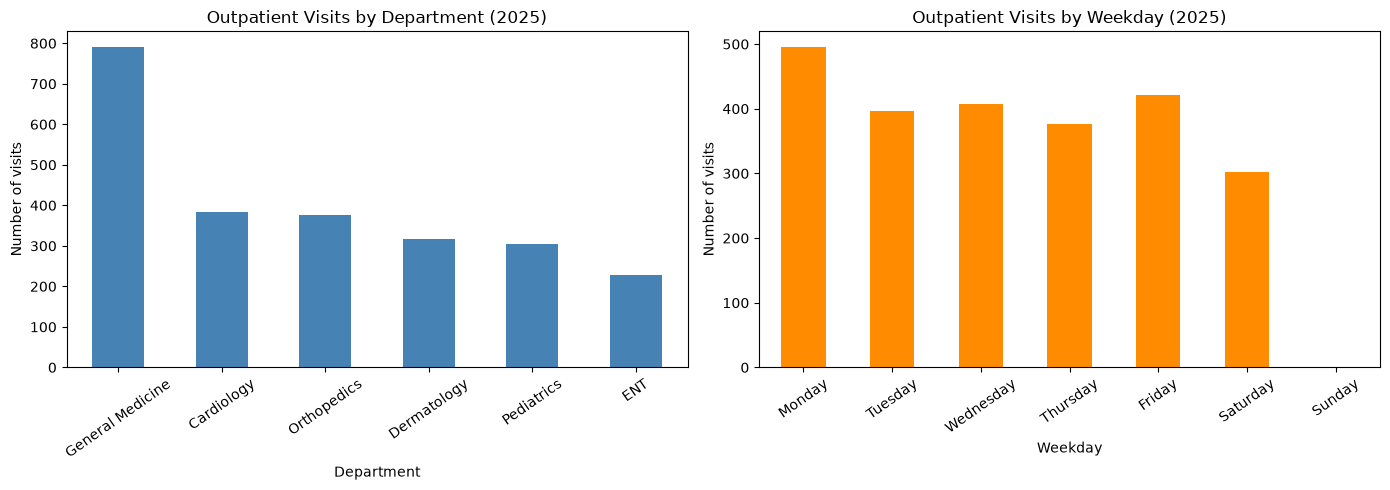

Busiest department: General Medicine ( 790 visits )
Busiest weekday: Monday ( 495 visits )


In [41]:
# Q1: department workload and weekday workload.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
department_counts = df["department"].value_counts().sort_values(ascending=False)
department_counts.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Outpatient Visits by Department (2025)")
axes[0].set_xlabel("Department"); axes[0].set_ylabel("Number of visits"); axes[0].tick_params(axis="x", rotation=35)
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_counts = df["weekday"].value_counts().reindex(weekday_order, fill_value=0)
weekday_counts.plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Outpatient Visits by Weekday (2025)")
axes[1].set_xlabel("Weekday"); axes[1].set_ylabel("Number of visits"); axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()
print("Busiest department:", department_counts.idxmax(), "(", int(department_counts.max()), "visits )")
print("Busiest weekday:", weekday_counts.idxmax(), "(", int(weekday_counts.max()), "visits )")

*Reading:* **General Medicine** is the busiest department (790 visits), and **Monday** is the busiest weekday (495 visits). Use these peaks to check Monday roster coverage and queue staffing; do not assume all weekdays need equal staffing.

### Q2. Where do patients wait longest?
Group wait time by department: mean, median, std, and the 90th percentile. Box plot. Reading: which department's *worst* days matter most?

,mean,median,std,p90
department,,,,
General Medicine,37.77,38.0,8.93,49.0
Cardiology,31.85,32.0,8.95,43.0
Orthopedics,25.87,26.0,8.85,37.0
ENT,20.14,19.0,9.03,32.4
Pediatrics,22.14,22.5,8.59,32.0
Dermatology,18.39,18.0,8.47,29.3


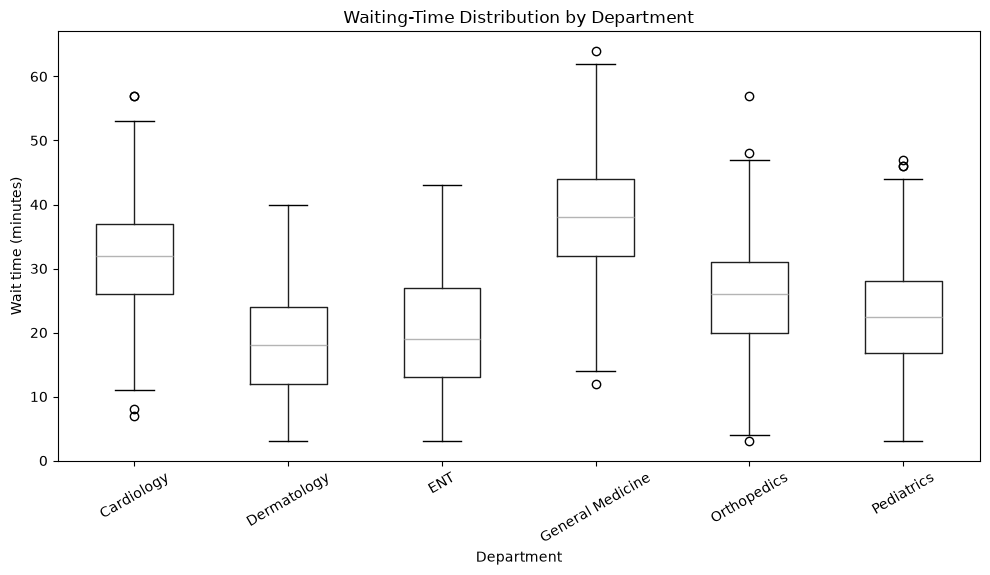

Highest 90th-percentile wait: General Medicine (49.0 minutes)


In [42]:
# Q2: distribution summary and box plot for waits by department.
wait_summary = df.groupby("department")["wait_minutes"].agg(
    mean="mean", median="median", std="std", p90=lambda s: s.quantile(0.90)
).sort_values("p90", ascending=False)
display(wait_summary.round(2))
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(column="wait_minutes", by="department", ax=ax, grid=False, rot=30)
ax.set_title("Waiting-Time Distribution by Department")
ax.set_xlabel("Department"); ax.set_ylabel("Wait time (minutes)")
fig.suptitle(""); plt.tight_layout(); plt.show()
print("Highest 90th-percentile wait:", wait_summary.index[0], f"({wait_summary.iloc[0]['p90']:.1f} minutes)")

*Reading:* **General Medicine** has the highest 90th-percentile wait at **49.0 minutes** (mean 37.8 minutes), so its longest-wait days deserve the first queue review; the p90 highlights the tail that a mean can hide.

### Q3. What does each department really earn per visit?
Mean vs median fee by department, with and without procedures. Reading: which number would you put in the annual report, and why?

All visits — fee summary (INR):


,visits,mean_fee,median_fee,max_fee
department,,,,
Cardiology,383,2021.41,1260.0,50000.0
Orthopedics,375,1972.75,1060.0,50000.0
Dermatology,318,846.64,850.0,1000.0
ENT,227,735.73,740.0,870.0
Pediatrics,304,631.91,630.0,750.0
General Medicine,790,522.32,520.0,620.0


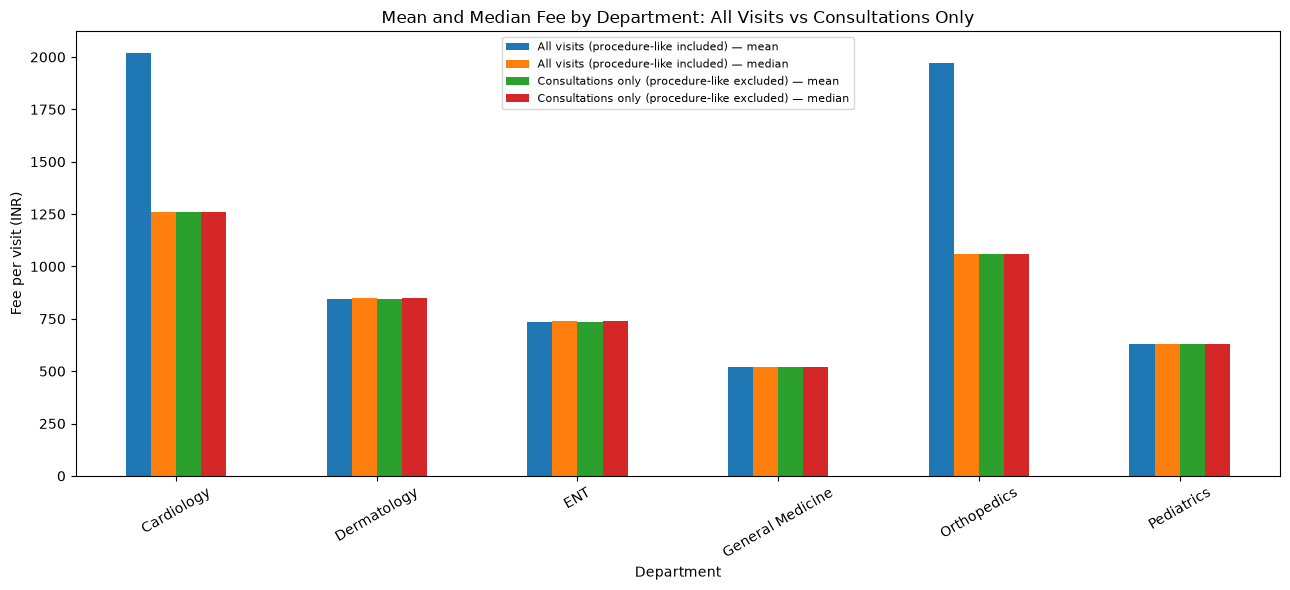

Cardiology mean/median: 2021.41 / 1260.0


In [43]:
# Q3: department fee summaries with and without procedure-like ₹50,000 charges.
fee_summary = df.groupby("department").agg(
    visits=("fee", "size"), mean_fee=("fee", "mean"), median_fee=("fee", "median"), max_fee=("fee", "max")
).sort_values("median_fee", ascending=False)
print("All visits — fee summary (INR):")
display(fee_summary.round(2))
fee_without_proc = df.loc[~df["is_procedure"]].groupby("department")["fee"].agg(mean="mean", median="median")
fee_with_proc = df.groupby("department")["fee"].agg(mean="mean", median="median")
comparison = pd.concat({"All visits (procedure-like included)": fee_with_proc, "Consultations only (procedure-like excluded)": fee_without_proc}, axis=1)
comparison.columns = [f"{a} — {b}" for a,b in comparison.columns]
fig, ax = plt.subplots(figsize=(13, 6))
comparison.plot(kind="bar", ax=ax)
ax.set_title("Mean and Median Fee by Department: All Visits vs Consultations Only")
ax.set_xlabel("Department"); ax.set_ylabel("Fee per visit (INR)"); ax.tick_params(axis="x", rotation=30)
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print("Cardiology mean/median:", round(df.loc[df.department.eq("Cardiology"), "fee"].mean(), 2), "/", round(df.loc[df.department.eq("Cardiology"), "fee"].median(), 2))

*Reading:* Cardiology’s mean fee is **₹2,021** versus a median of **₹1,260** because a small number of ₹50,000 procedure-like charges pull up the mean. Use the median for a typical-visit figure and report procedure revenue separately, after confirming billing codes.

### Q4. Does patient age relate to consultation length?
Scatter, `r`, `np.polyfit` line. Reading: how much longer per decade of age?

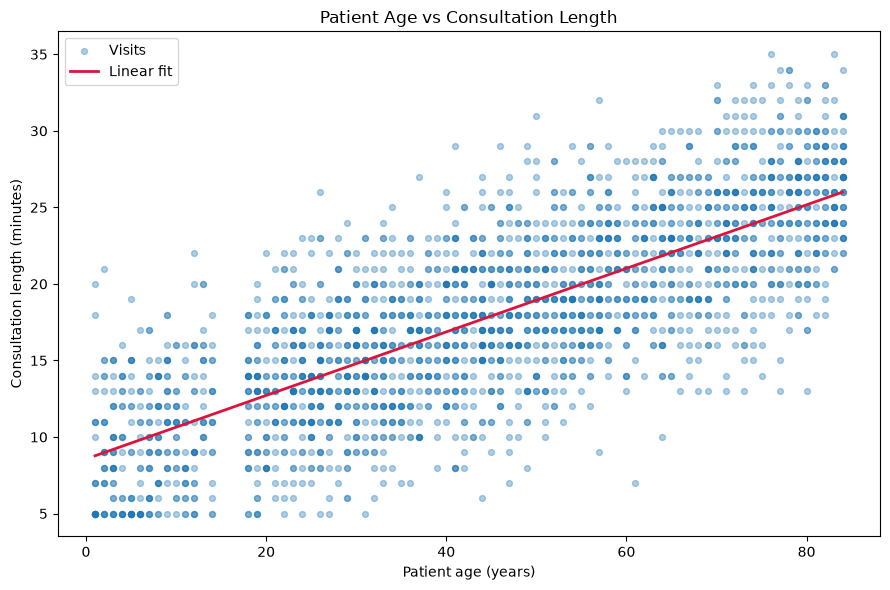

Pearson r = 0.767
Linear slope = 0.2075 minutes/year (2.08 minutes/decade)


In [44]:
# Q4: association between age and consultation length (association is not causation).
valid = df[["age", "consult_minutes"]].dropna()
x = valid["age"].to_numpy(dtype=float); y = valid["consult_minutes"].to_numpy(dtype=float)
r = float(np.corrcoef(x, y)[0, 1])
slope, intercept = np.polyfit(x, y, deg=1)
x_line = np.linspace(x.min(), x.max(), 100)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(x, y, alpha=0.35, s=18, label="Visits")
ax.plot(x_line, slope*x_line+intercept, color="crimson", linewidth=2, label="Linear fit")
ax.set_title("Patient Age vs Consultation Length")
ax.set_xlabel("Patient age (years)"); ax.set_ylabel("Consultation length (minutes)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Pearson r = {r:.3f}")
print(f"Linear slope = {slope:.4f} minutes/year ({slope*10:.2f} minutes/decade)")

*Reading:* Age and consultation length have a positive linear association in this dataset (**r = 0.77**); the fitted line rises by about **2.1 minutes per decade**. This is descriptive association, not proof that age causes longer consultations.

### Q5. Is the clinic getting busier? Monthly revenue trend
Line chart, all revenue vs consultations only. Reading: are the spikes growth or single events?

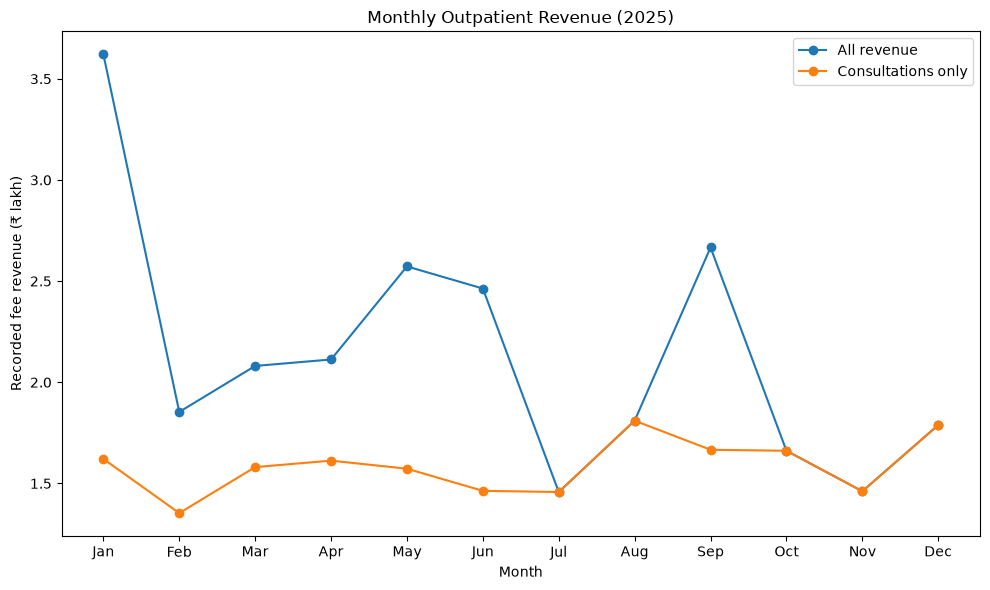

Highest revenue month: Jan (₹362,130)
Lowest revenue month: Jul (₹145,750)
Annual recorded revenue (all): ₹ 2,554,950


In [45]:
# Q5: monthly fee revenue, comparing all visits with consultation-only revenue.
month_order = list(range(1, 13))
monthly_all = df.groupby("month")["fee"].sum().reindex(month_order, fill_value=0)
monthly_consult = df.loc[~df["is_procedure"]].groupby("month")["fee"].sum().reindex(month_order, fill_value=0)
month_labels = [pd.Timestamp(2025, m, 1).strftime("%b") for m in month_order]
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(month_labels, monthly_all.values/100000, marker="o", label="All revenue")
ax.plot(month_labels, monthly_consult.values/100000, marker="o", label="Consultations only")
ax.set_title("Monthly Outpatient Revenue (2025)")
ax.set_xlabel("Month"); ax.set_ylabel("Recorded fee revenue (₹ lakh)"); ax.legend()
plt.tight_layout(); plt.show()
peak_month = int(monthly_all.idxmax()); low_month = int(monthly_all.idxmin())
print(f"Highest revenue month: {month_labels[peak_month-1]} (₹{monthly_all.max():,.0f})")
print(f"Lowest revenue month: {month_labels[low_month-1]} (₹{monthly_all.min():,.0f})")
print("Annual recorded revenue (all): ₹", f"{monthly_all.sum():,.0f}")

*Reading:* Recorded revenue peaks in **Jan (₹362,130)** and is lowest in **Jul (₹145,750)**. Check whether monthly peaks are driven by one-off ₹50,000 procedure-like charges before describing them as sustained growth.

---
## Session 3 — Section 4: Your own question

Pick **one** and take it further than the guided questions did — this is your headline finding and your slide 3.

1. **Doctor workload** — is any doctor carrying an unfair share of visits or wait time within their department?
2. **Follow-up compliance** — which departments/ages come back for follow-up, and which don't?
3. **Payment-mode trends** — is UPI displacing cash across the year? Does mode differ by city or age?
4. **City-wise access** — do out-of-city patients wait longer or pay more?
5. **Consultation efficiency** — wait vs consult ratio by department: where does the queue exceed the care?
6. **Revenue concentration** — what share of revenue comes from the top 10% of visits? Top 2 departments?

Requirements: at least one `groupby`, one chart, one statistic you can defend, and a sentence on what you'd need to be sure.

Top 10% of visits: 240 visits account for ₹955,400 (37.4% of recorded revenue)
Top two departments: Cardiology, Orthopedics account for 59.3% of recorded revenue


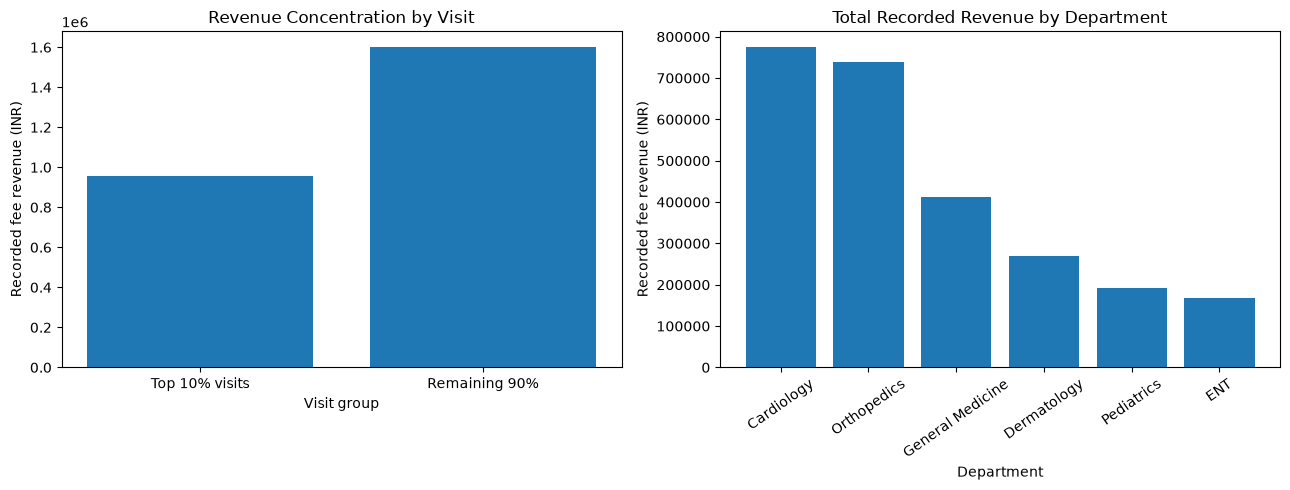

Statistic defended: revenue share is interpretable as concentration, but is sensitive to the provisional procedure flag and imputed fees.
What I would need to be sure: verified procedure/billing codes, itemised charges, and confirmation that missing fees are missing at random within department.


In [46]:
# Own question (option 6): revenue concentration — quantify how much revenue comes from top visits and departments.
# The top 10% is defined by number of visits, ranked by fee; imputed fees are included and procedure-like fees are retained.
ranked = df.sort_values("fee", ascending=False).reset_index(drop=True)
top_n = int(np.ceil(len(ranked) * 0.10))
total_revenue = df["fee"].sum()
top10_revenue = ranked.head(top_n)["fee"].sum()
top10_share = top10_revenue / total_revenue * 100
dept_revenue = df.groupby("department")["fee"].sum().sort_values(ascending=False)
top2_share = dept_revenue.head(2).sum() / total_revenue * 100
print(f"Top 10% of visits: {top_n} visits account for ₹{top10_revenue:,.0f} ({top10_share:.1f}% of recorded revenue)")
print(f"Top two departments: {', '.join(dept_revenue.head(2).index)} account for {top2_share:.1f}% of recorded revenue")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(["Top 10% visits", "Remaining 90%"], [top10_revenue, total_revenue-top10_revenue])
axes[0].set_title("Revenue Concentration by Visit")
axes[0].set_xlabel("Visit group"); axes[0].set_ylabel("Recorded fee revenue (INR)")
axes[1].bar(dept_revenue.index, dept_revenue.values)
axes[1].set_title("Total Recorded Revenue by Department")
axes[1].set_xlabel("Department"); axes[1].set_ylabel("Recorded fee revenue (INR)"); axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()
print("Statistic defended: revenue share is interpretable as concentration, but is sensitive to the provisional procedure flag and imputed fees.")
print("What I would need to be sure: verified procedure/billing codes, itemised charges, and confirmation that missing fees are missing at random within department.")

## Recommendation to the administrator

Administrator, the 2025 records show that General Medicine handled the most visits (790 of 2,397), so it should be the first place to review roster coverage and peak-hour queue management. Waiting-time comparisons show General Medicine has the highest 90th-percentile wait (49.0 minutes); review its appointment spacing, arrival surges and staff availability before making a permanent staffing change. The IQR rule flagged 13 high fees, but each was ₹50,000 in Cardiology or Orthopedics, so these values were retained and separately flagged rather than deleted; confirm their meaning against billing/procedure codes. Missing fees were filled with department medians, and three impossible-age records were excluded. In 2026, trial a targeted queue review in the highest-p90 department and track median and 90th-percentile wait weekly alongside visits per staffed hour. Before treating revenue changes as growth, validate procedure coding and investigate the Jan revenue peak. With appointment timestamps, staffing rosters and verified billing codes, the clinic could distinguish capacity problems from case mix and one-off charges.

---
## Section 6: Presentation

The companion files include a five-slide presentation and a two-minute pitch script. The notebook is designed to run top-to-bottom from the same folder as `clinic_visits_2025.csv`.

### The cliffhanger
`np.polyfit` fitted consult time from one column. To model it from age, department and doctor together, the next module introduces multi-feature predictive modelling; this project intentionally stays descriptive and uses no `sklearn`.